In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
SCRIPT_DIR = Path.cwd()
DATA_PATH = SCRIPT_DIR / "USSeatBelts.csv"
if not DATA_PATH.exists():
    DATA_PATH = SCRIPT_DIR.parent / "USSeatBelts.csv"
def load_seatbelts():
    if not DATA_PATH.exists():
        raise FileNotFoundError(
            f"Could not find {DATA_PATH.resolve()}. "
            "Place USSeatBelts.csv or USSeatBelts(5).csv in this folder."
        )
    return pd.read_csv(DATA_PATH)
def show_data(df):
    print("\nDATASET DIMENSIONS:", df.shape)
    print("\nCOLUMNS:", list(df.columns))
    print("\nDATA INFORMATION:")
    df.info()
    print("\nFIRST SIX ROWS:")
    print(df.head(6).to_string(index=False))
    print("\nSUMMARY STATISTICS:")
    print(df.describe(include="all").T.to_string())
df = load_seatbelts()
show_data(df)


DATASET DIMENSIONS: (765, 13)

COLUMNS: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

DATA INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    str    
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    str    
 7   speed70     765 non-null    str    
 8   drinkage    765 non-null    str    
 9   alcohol     765 non-null    str    
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    str    
dtypes: float64(3), int64(4), str(6)
memory usage: 77.8 KB

FIRST SIX ROWS:
 rownames state  

In [2]:
# Select numerical variables and exclude row identifiers
numeric = df.select_dtypes(include=np.number).copy()
numeric = numeric.drop(columns=["rownames"], errors="ignore")
numeric = numeric.dropna(axis=1, how="all")
print("\nMISSING VALUES BEFORE IMPUTATION:")
print(numeric.isnull().sum().to_string())
# Replace missing values with column medians
numeric = numeric.fillna(numeric.median())
# Remove constant columns
numeric = numeric.loc[:, numeric.nunique(dropna=True) > 1]
if numeric.shape[1] < 2:
    raise ValueError("PCA requires at least two non-constant numerical variables.")
# Standardize the data
scaler = StandardScaler()
data_scaled = pd.DataFrame(
    scaler.fit_transform(numeric),
    columns=numeric.columns,
    index=numeric.index
)
print("\nCLEANED SCALED DIMENSIONS:", data_scaled.shape)
print("\nSTANDARDIZED DATA (FIRST SIX ROWS):")
print(data_scaled.head(6).round(4).to_string())
print("\nSTANDARDIZED DATA SUMMARY:")
print(data_scaled.describe().round(4).to_string())
# Perform PCA
pca = PCA()
scores = pca.fit_transform(data_scaled)
variance = pca.explained_variance_ratio_ * 100


MISSING VALUES BEFORE IMPUTATION:
year            0
miles           0
fatalities      0
seatbelt      209
income          0
age             0

CLEANED SCALED DIMENSIONS: (765, 6)

STANDARDIZED DATA (FIRST SIX ROWS):
     year   miles  fatalities  seatbelt  income     age
0 -1.6202 -0.8670      3.7585    0.1058 -0.0041 -4.0673
1 -1.3887 -0.8617      2.5695    0.1058  0.0209 -4.0033
2 -1.1573 -0.8560      1.8782    0.1058  0.1939 -3.9860
3 -0.9258 -0.8522      0.6016    0.1058  0.0985 -3.9720
4 -0.6944 -0.8547     -0.3247    0.1058  0.0059 -3.9386
5 -0.4629 -0.8560      0.6104    0.1058  0.0945 -3.7040

STANDARDIZED DATA SUMMARY:
           year     miles  fatalities  seatbelt    income       age
count  765.0000  765.0000    765.0000  765.0000  765.0000  765.0000
mean     0.0000    0.0000     -0.0000    0.0000    0.0000   -0.0000
std      1.0007    1.0007      1.0007    1.0007    1.0007    1.0007
min     -1.6202   -0.8729     -2.1342   -3.2674   -2.0008   -4.0673
25%     -0.9258   -0.68


PCA SUMMARY TABLE:
Component  Eigenvalue  Variance_Percent  Cumulative_Percent
      PC1      2.9304           48.7764             48.7764
      PC2      0.9990           16.6277             65.4040
      PC3      0.8820           14.6812             80.0853
      PC4      0.6209           10.3351             90.4203
      PC5      0.3946            6.5684             96.9887
      PC6      0.1809            3.0113            100.0000


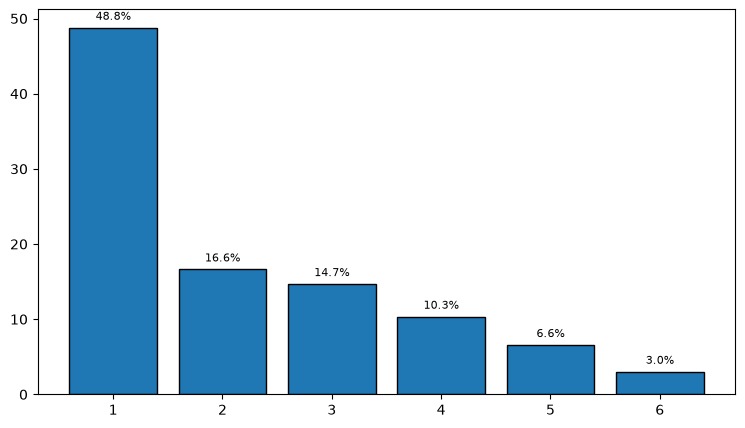

In [3]:
cumulative_variance = np.cumsum(variance)
# PCA summary table
pca_summary = pd.DataFrame({
    "Component": [f"PC{i + 1}" for i in range(len(variance))],
    "Eigenvalue": pca.explained_variance_,
    "Variance_Percent": variance,
    "Cumulative_Percent": cumulative_variance
})
print("\nPCA SUMMARY TABLE:")
print(pca_summary.round(4).to_string(index=False))
# Scree plot with y-axis from 0 to 60
plt.figure(figsize=(9, 5))
components = np.arange(1, len(variance) + 1)
plt.bar(
    components,
    variance,
    edgecolor="black"
)
for i, value in enumerate(variance):
    if value <= 60:
        plt.text(
            i + 1,
            value + 0.7,
            f"{value:.1f}%",
            ha="center",
            va="bottom",
            fontsize=8
        )

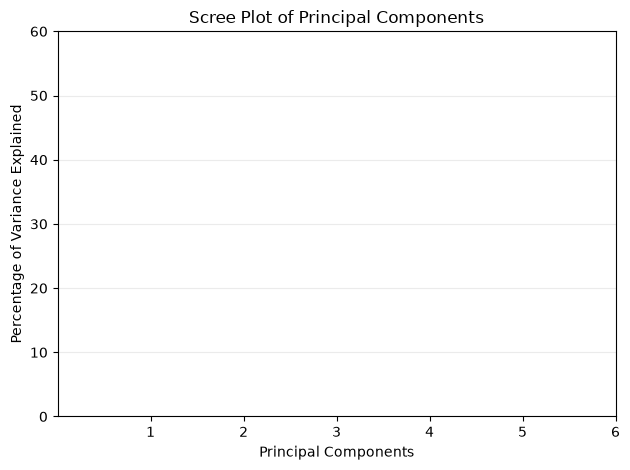


NUMBER OF PCs REQUIRED FOR AT LEAST 80% VARIANCE: 3
CUMULATIVE VARIANCE EXPLAINED: 80.09%


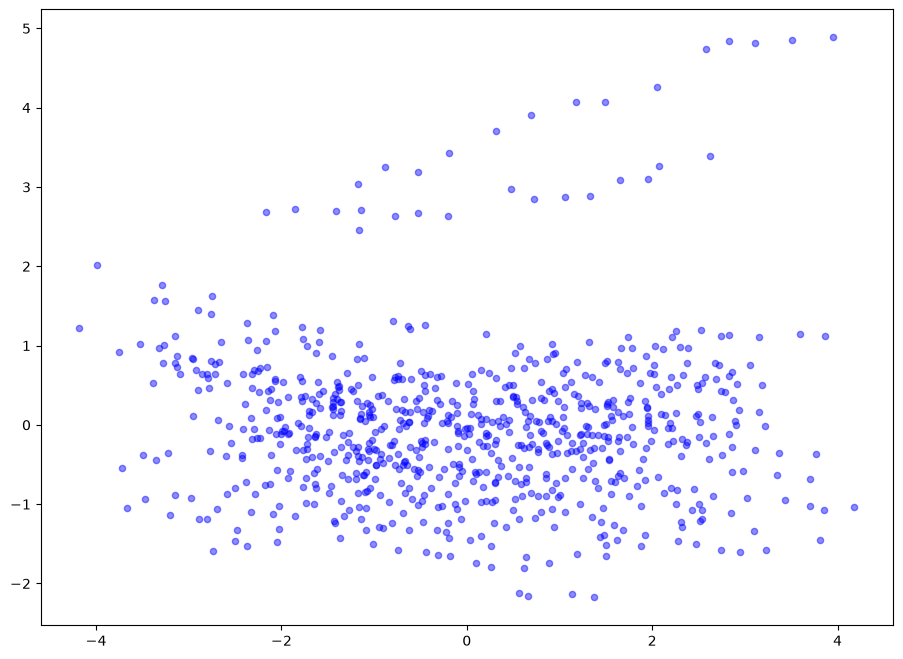

In [4]:
plt.xticks(components)
plt.yticks(np.arange(0, 61, 10))
plt.ylim(0, 60)
plt.xlabel("Principal Components")
plt.ylabel("Percentage of Variance Explained")
plt.title("Scree Plot of Principal Components")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
# Determine number of PCs explaining at least 80% variance
num_pc = np.argmax(cumulative_variance >= 80) + 1
print(f"\nNUMBER OF PCs REQUIRED FOR AT LEAST 80% VARIANCE: {num_pc}")
print(f"CUMULATIVE VARIANCE EXPLAINED: {cumulative_variance[num_pc - 1]:.2f}%")
# PCA loadings for the first two components
loadings = pca.components_.T[:, :2]
# Biplot-style view: scores and variable loading arrows
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(
    scores[:, 0],
    scores[:, 1],
    color="blue",
    alpha=0.45,
    s=20
)

In [5]:
# Scale arrows relative to score range
score_range = max(
    np.ptp(scores[:, 0]),
    np.ptp(scores[:, 1]),
    1
)
arrow_scale = score_range * 0.18
for i, name in enumerate(data_scaled.columns):
    dx = loadings[i, 0] * arrow_scale
    dy = loadings[i, 1] * arrow_scale

    ax.annotate(
        "",
        xy=(dx, dy),
        xytext=(0, 0),
        arrowprops=dict(arrowstyle="->", color="red", lw=1.2)
    )

    ax.annotate(
        name,
        (dx, dy),
        xytext=(4, 4),
        textcoords="offset points",
        color="darkred",
        fontsize=8
    )
ax.axhline(0, color="grey", linewidth=0.7)
ax.axvline(0, color="grey", linewidth=0.7)

<Figure size 640x480 with 0 Axes>


FIRST SIX PCA SCORES:
      PC1     PC2     PC3     PC4     PC5     PC6
0 -3.9860  2.0100 -2.6975 -0.5832  1.4869  2.0740
1 -3.2847  1.7643 -2.5733 -1.1733  0.9014  1.6118
2 -2.7492  1.6205 -2.5400 -1.5669  0.6525  1.4213
3 -2.0886  1.3856 -2.4220 -2.2123 -0.0024  0.8367
4 -1.5834  1.1974 -2.3393 -2.6651 -0.4415  0.3616
5 -1.7763  1.2317 -2.3866 -2.0620  0.2870  0.5972


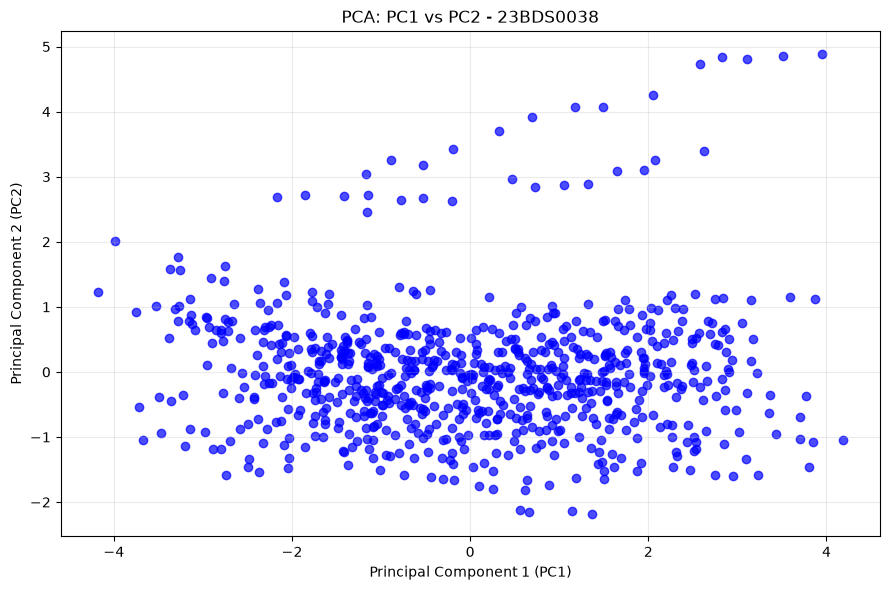

In [6]:
ax.set_title("PCA Biplot of US Seat Belt Dataset")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
# Save PCA scores for all principal components
pca_scores = pd.DataFrame(
    scores,
    columns=[f"PC{i + 1}" for i in range(scores.shape[1])],
    index=df.index
)
print("\nFIRST SIX PCA SCORES:")
print(pca_scores.head(6).round(4).to_string())
# PC1 versus PC2 scatter plot
plt.figure(figsize=(9, 6))
plt.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    color="blue",
    marker="o",
    alpha=0.7
)
plt.title("PCA: PC1 vs PC2 - 23BDS0038")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.grid(alpha=0.25)
plt.tight_layout()